In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
%matplotlib inline

In [4]:
df = pd.read_csv('Titanic-Dataset.csv')
print(df.shape)
print(f'Количество дубликатов: {df.duplicated().sum()}')
df

(891, 12)
Количество дубликатов: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [5]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [6]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Survived'])
y = df['Survived']

def add_features(X_train, X_test):
    X_train, X_test = X_train.copy(), X_test.copy()

    for dataset in (X_train, X_test):
        dataset['Title'] = dataset['Name'].str.extract(r'([A-Za-z]+)\.')
        dataset['Title'] = dataset['Title'].replace(['Mlle', 'Ms'], 'Miss').replace('Mme', 'Mrs')
        dataset.loc[~dataset['Title'].isin(['Miss', 'Mr', 'Mrs', 'Master']), 'Title'] = 'Rare'
        dataset['deck'] = dataset['Cabin'].str[0].fillna('U')

    age_medians = X_train.groupby(['Title', 'Pclass'])['Age'].median()

    for dataset in (X_train, X_test):
        medians_series = dataset.set_index(['Title', 'Pclass']).index.map(age_medians)
        dataset['Age'] = dataset['Age'].fillna(pd.Series(medians_series, index=dataset.index))

    return X_train, X_test

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_test = add_features(X_train, X_test)
train = X_train.assign(Survived=y_train)

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

num = ['Age', 'Fare', 'SibSp', 'Parch']
cat = ['Pclass', 'Sex', 'Embarked', 'Title', 'deck']


preprocess = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ]), num),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat)
])

preprocess_scaled = ColumnTransformer([
    ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
    ]),num,),
    ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), cat)
 ])


preprocess.set_output(transform="pandas")
X_ready = preprocess.fit_transform(X_train)
train = X_ready.assign(Survived=y_train)
train.head()

,num__Age,num__Fare,num__SibSp,num__Parch,cat__Pclass_1,cat__Pclass_2,cat__Pclass_3,cat__Sex_female,cat__Sex_male,cat__Embarked_C,...,cat__deck_A,cat__deck_B,cat__deck_C,cat__deck_D,cat__deck_E,cat__deck_F,cat__deck_G,cat__deck_T,cat__deck_U,Survived
692,27.0,56.4958,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
481,30.0,0.0000,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
527,40.0,221.7792,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0
855,18.0,9.3500,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
801,31.0,26.2500,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1


In [8]:
stats = train.describe().T[['mean', 'std', 'min', '50%', 'max']]
stats['skew'] = train.skew()
stats['kurtosis'] = train.kurtosis()
stats

,mean,std,min,50%,max,skew,kurtosis
num__Age,29.398062,13.460508,0.42,27.0000,80.0000,0.414067,0.597859
num__Fare,31.819826,48.059104,0.00,14.4542,512.3292,4.646190,32.518880
num__SibSp,0.492978,1.060720,0.00,0.0000,8.0000,3.815617,19.317828
num__Parch,0.390449,0.838134,0.00,0.0000,6.0000,2.842562,10.190391
cat__Pclass_1,0.240169,0.427486,0.00,0.0000,1.0000,1.219050,-0.515373
cat__Pclass_2,0.210674,0.408074,0.00,0.0000,1.0000,1.422001,0.022141
cat__Pclass_3,0.549157,0.497927,0.00,1.0000,1.0000,-0.198004,-1.966326
cat__Sex_female,0.355337,0.478952,0.00,0.0000,1.0000,0.605783,-1.637635
cat__Sex_male,0.644663,0.478952,0.00,1.0000,1.0000,-0.605783,-1.637635
cat__Embarked_C,0.195225,0.396652,0.00,0.0000,1.0000,1.541067,0.375935


In [9]:
y_train.value_counts(sort=False)

,count
Survived,
1,273
0,439


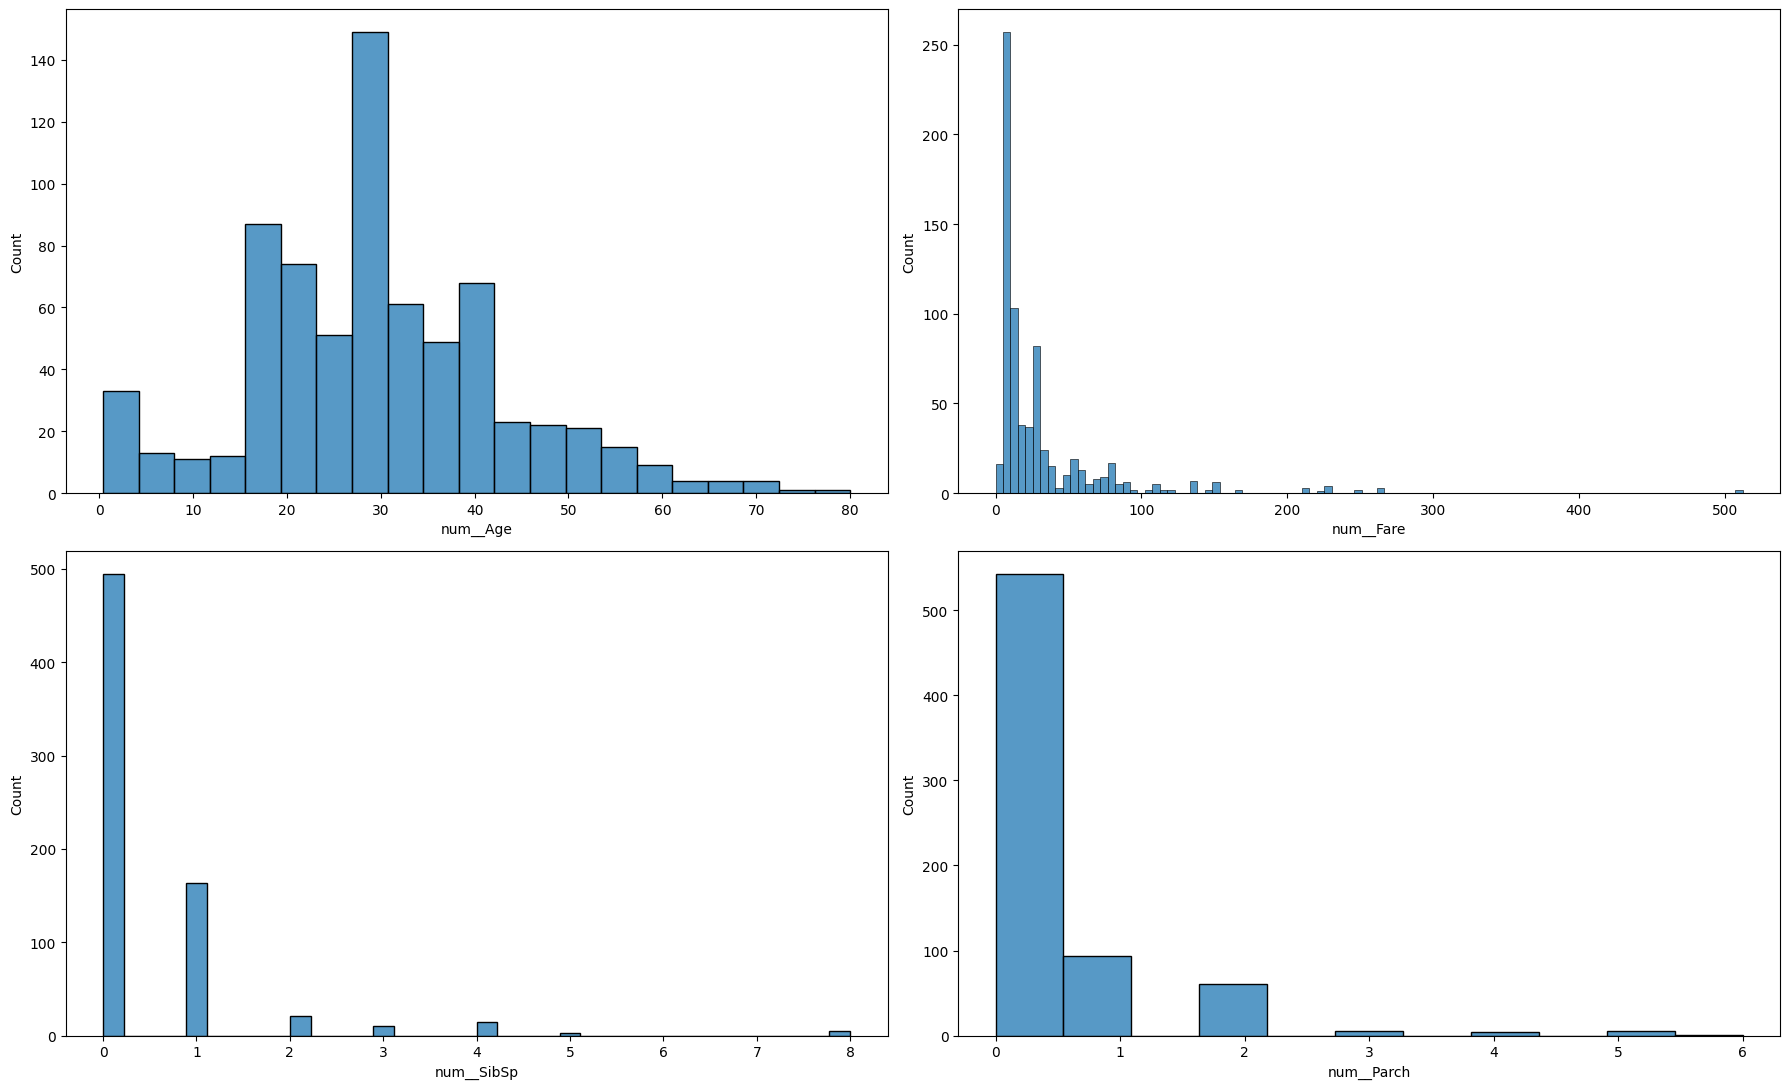

In [10]:
feat_cols = train.filter(like='num').columns

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, c in zip(axes.ravel(), feat_cols):
    sns.histplot(train[c], ax=ax)

plt.tight_layout()
plt.show()

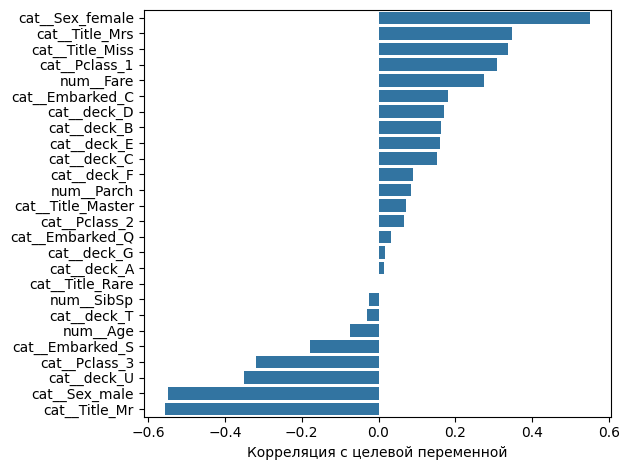

In [11]:
correlations = X_ready.corrwith(y_train).sort_values(ascending=False)
plot = sns.barplot(y=correlations.index, x=correlations)

plot.set(xlabel="Корреляция с целевой переменной", ylabel="")

plt.tight_layout()
plt.show()

<Axes: >

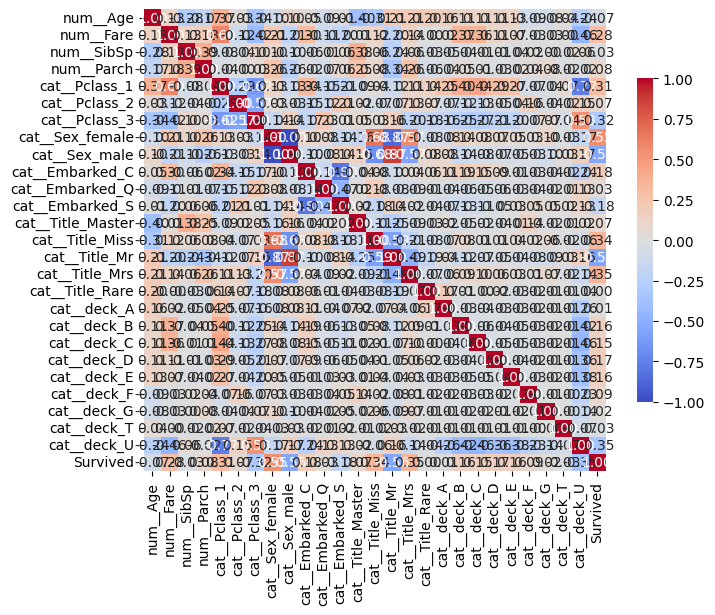

In [12]:
corr_matrix = train.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, cbar_kws={'shrink': 0.7})

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

baseline = DummyClassifier(strategy='most_frequent')
tree = Pipeline([
    ('prep', preprocess),
    ('model', DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=5,
        random_state=42
    ))
])
rf = Pipeline([
    ('prep', preprocess),
    ('model', RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])
gb = Pipeline([
    ('prep', preprocess),
    ('model',GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ))
])
svm = Pipeline([
    ('prep', preprocess_scaled),
    ('model', SVC(
        C=1.0,
        kernel='rbf',
        gamma='scale',
        probability=True
    ))
])
knn = Pipeline([
    ('prep', preprocess_scaled),
    ('model', KNeighborsClassifier(
        n_neighbors=7,
        weights='distance'
    ))
])


def evaluate(name, model, X_test, y_test):
  pred = model.predict(X_test)
  proba = model.predict_proba(X_test)[:, 1]
  return {
      'model': name,
      'accuracy': accuracy_score(y_test, pred),
      'precision': precision_score(y_test, pred, zero_division=0),
      'recall': recall_score(y_test, pred, zero_division=0),
      'f1': f1_score(y_test, pred, zero_division=0),
      'roc_auc': roc_auc_score(y_test, proba)
  }

models = {
    'baseline': baseline,
    'Decision Tree': tree,
    'Random Forest': rf,
    'Gradient Boosting': gb,
    'SVM': svm,
    'KNN': knn
}

results = []
coefs = []
for name, model in models.items():
  model.fit(X_train, y_train)
  results.append(evaluate(name, model, X_test, y_test))

results = (pd.DataFrame(results).sort_values('f1', ascending=False))
results



,model,accuracy,precision,recall,f1,roc_auc
4,SVM,0.837989,0.833333,0.724638,0.775194,0.854150
5,KNN,0.798883,0.753846,0.710145,0.731343,0.829644
3,Gradient Boosting,0.804469,0.793103,0.666667,0.724409,0.844862
2,Random Forest,0.804469,0.803571,0.652174,0.720000,0.848287
1,Decision Tree,0.798883,0.811321,0.623188,0.704918,0.829447
0,baseline,0.614525,0.000000,0.000000,0.000000,0.500000


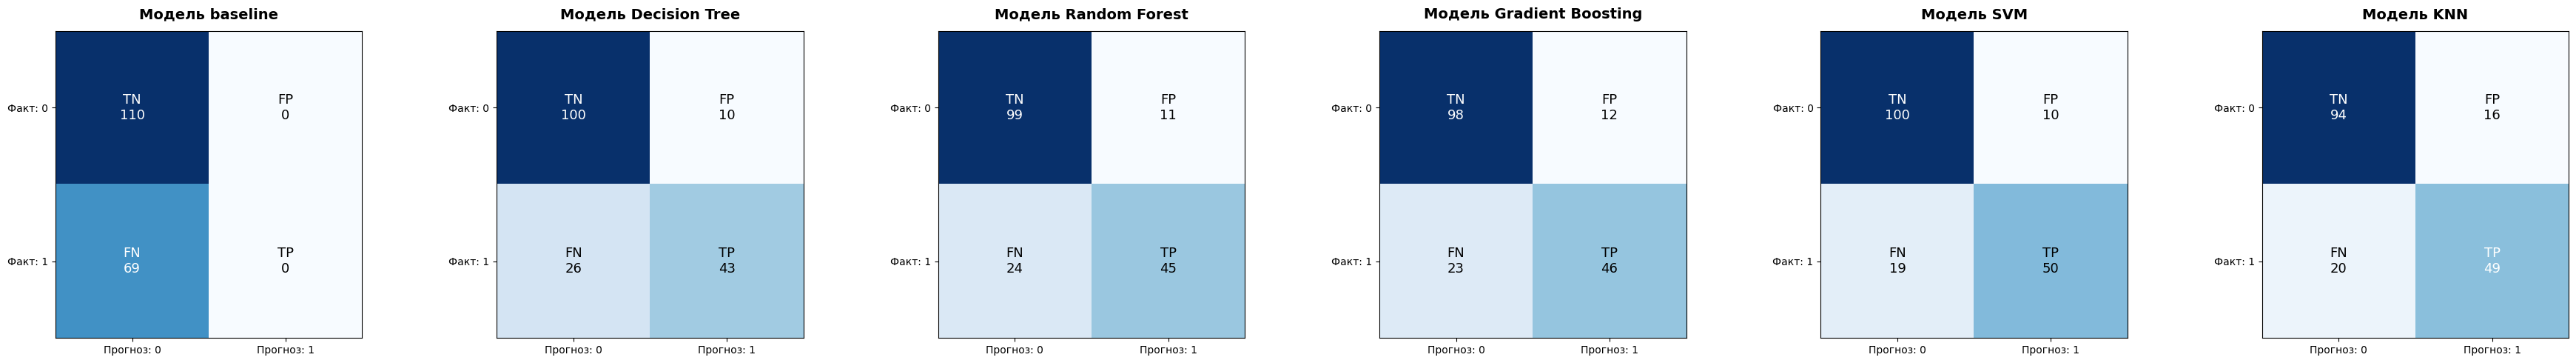

In [14]:
from sklearn.metrics import confusion_matrix

def draw_conf_matrix(y_test, pred, title, ax=None):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    im = ax.imshow(cm, cmap='Blues')
    for (r, col), value in np.ndenumerate(cm):
        name = {(0, 0): 'TN', (0, 1): 'FP', (1, 0): 'FN', (1, 1): 'TP'}[(r, col)]
        ax.text(col, r, f'{name}\n{value}', ha='center', va='center', fontsize=13,
                color='white' if value > cm.max() / 2 else 'black')

    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.set_xticks([0, 1], ['Прогноз: 0', 'Прогноз: 1'])
    ax.set_yticks([0, 1], ['Факт: 0', 'Факт: 1'])

n_models = len(models)
fig, axes = plt.subplots(ncols=n_models, figsize=(6 * n_models, 5))
axes = np.atleast_1d(axes)

for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    draw_conf_matrix(y_test, pred, f'Модель {name}', ax=ax)

plt.tight_layout()
plt.show()


